# AIDA 2156 Final Project – 03 Relationships, Within-Group Comparisons and Uncertainty

**Data version 2** (`shared/synthetic-data/`), cleaning version 1.1, using notebook 02's processing times for the 4,319 requests the team had finished by the extract date.

**Question:** How does processing time relate to task type, missing or conflicting information, team workload, submission timing and intake channel? Do those differences change when groups are compared within a common mix of recorded characteristics, and how uncertain are they?

This is steps 4 and 5 of the final project. Notebook 02 described how long requests took; this notebook compares groups. Initial exploration identified possible differences in group composition (for example, information issues are more common for some intake channels, and team workload differs by task type). The notebook checks whether descriptive comparisons change when the groups are compared within a common mix of recorded characteristics. Some comparisons may simply confirm that a difference is small.

The 13 comparisons that receive confidence intervals were specified before the bootstrap analysis, after the initial exploration. Intervals resample whole employees, because several requests can belong to the same employee. They are descriptive estimates with uncertainty: no p-values are calculated and no difference is called significant.

All records are synthetic. Differences occur in generated data shaped by task-type, workload, timing and delay assumptions; this analysis describes associations, not causes, and says nothing about real employees or real HR performance.

In [1]:
import hashlib
import json
from datetime import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(exist_ok=True)

read = lambda path: pd.read_csv(path, dtype=str, keep_default_na=False)
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()

requests = read(SD / "cleaning/output/requests_cleaned.csv")
cleaning_info = json.loads((SD / "cleaning/output/requests_cleaned_info.json").read_text())
assert sha(SD / "cleaning/output/requests_cleaned.csv") == cleaning_info["output_sha256"], \
    "The cleaned file doesn't match its cleaning record"

# Working calendar saved by notebook 02; the generator must be unchanged since then
calendar = json.loads((OUTPUT_DIR / "working_calendar.json").read_text())
assert sha(SD / "requests/generate_requests.py") == calendar["generator_sha256"], \
    "The generator has changed since notebook 02 saved the working calendar"
CLOSURES = {pd.Timestamp(d).date() for d in calendar["closure_dates"]}
DAY_START, DAY_END = time.fromisoformat(calendar["day_start"]), time.fromisoformat(calendar["day_end"])
EXTRACT_AT = pd.Timestamp(calendar["extract_at"])

# Notebook 02's completed requests (processing time in working-day equivalents)
completed = pd.read_csv(OUTPUT_DIR / "processing_times_completed.csv")
groups_02 = pd.read_csv(OUTPUT_DIR / "request_groups.csv", index_col=0)["requests"]
assert completed["request_id"].is_unique and len(completed) == groups_02["completed"], \
    "notebook 02's completed table doesn't match its request groups"
assert completed["info_issue_at_intake"].isin([True, False]).all(), "Unexpected information-issue values"
assert completed["processing_days"].notna().all() and np.isfinite(completed["processing_days"]).all()

# Rebuild notebook 02's eligibility from the current cleaned data: all four stage timestamps present,
# team completion no later than the extract. The saved table must hold exactly those requests,
# with the same employee, task type and information-issue values.
STAGE_TIMES = ["submitted_at", "info_complete_at", "assigned_at", "team_completed_at"]
stage = requests[STAGE_TIMES].apply(lambda c: pd.to_datetime(c.replace("", None), format="%Y-%m-%dT%H:%M"))
eligible = requests.loc[stage.notna().all(axis=1) & (stage["team_completed_at"] <= EXTRACT_AT), "request_id"]
assert set(completed["request_id"]) == set(eligible), "notebook 02's completed requests differ from the rebuilt eligibility"
source = requests.set_index("request_id").loc[completed["request_id"]]
assert (completed["employee_id"].to_numpy() == source["employee_id"].to_numpy()).all(), "Employee IDs differ"
assert (completed["task_type"].to_numpy() == source["task_type"].to_numpy()).all(), "Task types differ"
assert (completed["info_issue_at_intake"].astype(str).to_numpy() == source["info_issue_at_intake"].to_numpy()).all(), \
    "Information-issue values differ"

# Record which inputs this analysis used
inputs_record = {"data_version": DATA_VERSION, "cleaning_version": cleaning_info["cleaning_version"],
                 "inputs_sha256": {"requests_cleaned.csv": cleaning_info["output_sha256"],
                                   "processing_times_completed.csv (notebook 02)": sha(OUTPUT_DIR / "processing_times_completed.csv"),
                                   "working_calendar.json (notebook 02)": sha(OUTPUT_DIR / "working_calendar.json")}}
(OUTPUT_DIR / "analysis_inputs_03.json").write_text(json.dumps(inputs_record, indent=2))

print(f"Data version {DATA_VERSION}; cleaning version {cleaning_info['cleaning_version']}; extract {EXTRACT_AT:%Y-%m-%d %H:%M}")
print(f"{len(completed):,} completed requests from {completed['employee_id'].nunique():,} employees "
      f"({len(requests):,} cleaned requests in total)")

Data version 2; cleaning version 1.1; extract 2026-09-29 17:00
4,319 completed requests from 1,065 employees (4,364 cleaned requests in total)


## A. Definitions

**Processing time** is notebook 02's measure: working time from submission to team completion, in working-day equivalents (working hours ÷ 8.5).

**Variables compared**

- **Task type, intake channel, hiring department, employee type, information issue at intake:** recorded on the cleaned request. A missing intake channel is kept as its own group, `unknown`, and shown in every table; it is left out only of the phone and email comparisons with web forms.
- **After-hours submission:** submitted on a weekend, on a simulated closure date, or before 08:00 or after 16:30 on a working day. Exactly 08:00 and 16:30 count as working time, matching the generator's rule for working moments. The calendar is the one notebook 02 saved.
- **Workload at assignment:** the number of other tasks for the same team that were assigned strictly before this task was assigned and finished strictly after it (or were still unfinished at the extract). This follows the data card's definition and uses all cleaned requests. It is not a characteristic of the request at submission: it reflects timing, task mix and workflow conditions.
- **Workload groups:** the cutoffs are the lower and upper quartiles of workload across all 4,319 completed requests. **Low** is at or below the lower quartile and **high** is at or above the upper quartile, so tied values join the outer group and each group can hold more than a quarter of requests; the sizes are reported. The same overall cutoffs are used inside each task type.
- **Spring:** March to May, by submission date.

**The 13 contrasts with intervals** (always *comparison group minus reference group*, in working-day equivalents of median processing time):

| # | Comparison − reference | Summary |
|---|---|---|
| 1–4 | Equipment setup, system access, workplace access, orientation scheduling − payroll setup | Raw median difference |
| 5 | Information issue − no information issue | Raw median difference |
| 6 | High − low workload | Raw median difference |
| 7 | High − low workload, within task type | Weighted within-stratum median difference |
| 8 | After-hours − working-hours submission | Raw median difference |
| 9 | After-hours − working-hours, within information issue × task type | Weighted within-stratum median difference |
| 10 | Phone − web form | Raw median difference |
| 11 | Phone − web form, within information issue | Weighted within-stratum median difference |
| 12 | Email − web form | Raw median difference |
| 13 | Email − web form, within information issue | Weighted within-stratum median difference |

Payroll setup is the reference task type because it is operationally meaningful: every new employee needs pay set up before their first pay date, so it is a natural baseline for the other setup tasks. It is also the largest task group.

**Weighted within-stratum median difference.** Within each stratum (for example, each task type), the median of the comparison group minus the median of the reference group; those differences are then averaged using fixed weights. The common target is **all 4,319 completed requests**: each stratum's weight is its share of all completed requests. A stratum is included in the weighted estimate when each comparison group has at least 5 requests in it. This is a calculation rule, not a guarantee of precision; request and employee counts are reported for both sides. Strata that don't meet it are listed and left out, the weights are rescaled once over the included strata, and the share of all completed requests retained (**coverage**) is reported; the estimate then applies to the included strata only. This is a descriptive summary, not the difference between two standardised population medians and not a causal effect. The raw median difference is always shown beside it, because the two answer different questions.

**Interpretation limits.** Information issues are directly connected to the information-check stage, so their total-duration difference largely reflects that stage; it does not on its own show an effect on later team processing. Workload at assignment is an association measure, and comparing within task type does not make it causal.

In [2]:
r = requests.copy()
for c in ["submitted_at", "assigned_at", "team_completed_at"]:
    r[c] = pd.to_datetime(r[c].replace("", None), format="%Y-%m-%dT%H:%M")

# Workload at assignment (data card definition), using all cleaned requests with an assignment time
assigned = r[r["assigned_at"].notna()]
workload = {}
for team, g in assigned.groupby("responsible_team"):
    a = g["assigned_at"].to_numpy()
    done = g["team_completed_at"].fillna(pd.Timestamp.max).to_numpy()       # unfinished: still open after any time
    for rid, t in zip(g["request_id"], a):
        workload[rid] = int(((a < t) & (done > t)).sum())

d = completed.merge(r[["request_id", "employee_id", "responsible_team", "intake_channel", "hiring_department",
                       "employee_type", "submitted_at", "assigned_at"]],
                    on="request_id", how="left", validate="one_to_one", suffixes=("", "_cleaned"))
assert (d["employee_id"] == d["employee_id_cleaned"]).all(), "Employee IDs differ from the cleaned requests"
d = d.drop(columns="employee_id_cleaned")
d["intake_channel"] = d["intake_channel"].replace("", "unknown")
d["workload_at_assignment"] = d["request_id"].map(workload)
assert d["workload_at_assignment"].notna().all(), "Every completed request should have a workload at assignment"

s = d["submitted_at"]
assert s.notna().all(), "Every included request needs a submission timestamp"
assert s.le(EXTRACT_AT).all(), "A submission occurs after extraction"
in_hours = s.dt.time.between(DAY_START, DAY_END, inclusive="both")    # 08:00 and 16:30 count as working time
d["after_hours"] = (s.dt.weekday >= 5) | s.dt.date.isin(CLOSURES) | ~in_hours
d["spring"] = s.dt.month.isin([3, 4, 5])

Q1, Q3 = d["workload_at_assignment"].quantile([0.25, 0.75])
assert Q1 < Q3, "Workload quartiles coincide; low and high groups need a different definition"
d["workload_group"] = np.select([d["workload_at_assignment"] <= Q1, d["workload_at_assignment"] >= Q3],
                                ["low", "high"], default="middle")
print(f"Workload at assignment: quartile cutoffs {Q1:g} and {Q3:g} open tasks; "
      f"groups: {d['workload_group'].value_counts().reindex(['low', 'middle', 'high']).to_dict()}")
print(f"After-hours submissions: {int(d['after_hours'].sum()):,} of {len(d):,} completed requests "
      f"({100 * d['after_hours'].mean():.1f}%)")
print(f"Unknown intake channel: {int((d['intake_channel'] == 'unknown').sum())} completed requests "
      "(kept as a group; excluded only from the phone/email comparisons)")

Workload at assignment: quartile cutoffs 9 and 22 open tasks; groups: {'low': 1160, 'middle': 2027, 'high': 1132}
After-hours submissions: 650 of 4,319 completed requests (15.0%)
Unknown intake channel: 44 completed requests (kept as a group; excluded only from the phone/email comparisons)


## B. Descriptive relationships

The first table gives the median, quartiles, IQR and counts of processing time for each variable. The composition tables that follow show how the variables relate to each other: information issues by channel, after-hours submissions and workload by task type, and task mix by channel, each with its counts. These composition tables identify recorded differences worth considering in the within-group comparisons. They do not establish that those differences explain the processing-time patterns.

In [3]:
def describe_group(x):
    q1, med, q3 = x["processing_days"].quantile([0.25, 0.5, 0.75])
    return pd.Series({"requests": len(x), "employees": x["employee_id"].nunique(),
                      "median_days": med, "q1_days": q1, "q3_days": q3, "iqr_days": q3 - q1})


VARIABLES = ["task_type", "info_issue_at_intake", "workload_group", "after_hours", "intake_channel",
             "hiring_department", "employee_type"]
assert d[VARIABLES].notna().all().all(), "Missing grouping values would be omitted by groupby"
assert d["info_issue_at_intake"].isin([True, False]).all() and d["after_hours"].isin([True, False]).all()
by_variable = pd.concat({v: d.groupby(v).apply(describe_group, include_groups=False) for v in VARIABLES},
                        names=["variable", "group"])
by_variable[["requests", "employees"]] = by_variable[["requests", "employees"]].astype(int)
by_variable.to_csv(OUTPUT_DIR / "processing_time_by_variable.csv")
print("Processing time (working-day equivalents) by variable:")
display(by_variable.round(2))

# Composition tables, each with its counts
issue_by_channel = d.groupby("intake_channel").agg(
    requests=("request_id", "size"), with_information_issue=("info_issue_at_intake", "sum"),
    employees=("employee_id", "nunique"))
issue_by_channel["information_issue_%"] = 100 * issue_by_channel["with_information_issue"] / issue_by_channel["requests"]
after_hours_by_task = d.groupby("task_type").agg(
    requests=("request_id", "size"), after_hours=("after_hours", "sum"), employees=("employee_id", "nunique"))
after_hours_by_task["after_hours_%"] = 100 * after_hours_by_task["after_hours"] / after_hours_by_task["requests"]
workload_by_task = d.groupby("task_type").agg(
    requests=("request_id", "size"), employees=("employee_id", "nunique"),
    median_open_tasks=("workload_at_assignment", "median"))
task_mix_counts = pd.crosstab(d["intake_channel"], d["task_type"])
task_mix_pct = task_mix_counts.div(task_mix_counts.sum(axis=1), axis=0).mul(100)
COMPOSITION = {"information issues by channel": (issue_by_channel, "composition_information_issue_by_channel.csv"),
               "after-hours submissions by task type": (after_hours_by_task, "composition_after_hours_by_task_type.csv"),
               "workload at assignment by task type": (workload_by_task, "composition_workload_by_task_type.csv"),
               "task mix within each channel (requests)": (task_mix_counts, "task_mix_by_channel_counts.csv"),
               "task mix within each channel (% of the channel's requests)": (task_mix_pct, "task_mix_by_channel_pct.csv")}
for name, (table, file) in COMPOSITION.items():
    table.to_csv(OUTPUT_DIR / file)
    print(f"{name.capitalize()}:")
    display(table.round(1))

Processing time (working-day equivalents) by variable:


requests  employees  median_days  \
variable             group                                                      
task_type            equipment_setup              632        632         5.70   
                     orientation_scheduling       901        901         3.87   
                     payroll_setup               1061       1061         5.04   
                     system_access               1059       1059         4.23   
                     workplace_access             666        666         4.85   
info_issue_at_intake False                       3756       1065         4.35   
                     True                         563        453         7.16   
workload_group       high                        1132        628         4.99   
                     low                         1160        643         4.40   
                     middle                      2027        988         4.58   
after_hours          False                       3669       1062         4.61   
                     True                         650        511         4.85   
intake_channel       email                       1373        824         4.68   
                     phone                        668        492         4.58   
                     unknown                       44         44         4.64   
                     web_form                    2234        987         4.66   
hiring_department    Administration               610        150         4.69   
                     Finance                      402         99         4.75   
                     Parks                        963        240         4.59   
                     Recreation                   840        203         4.83   
                     Transit                      883        220         4.70   
                     Utilities                    621        153         4.43   
employee_type        permanent                   2291        566         4.65   
                     seasonal                    1115        274         4.66   
                     temporary                    913        225         4.69   

                                             q1_days  q3_days  iqr_days  
variable             group                                               
task_type            equipment_setup            4.40     7.45      3.06  
                     orientation_scheduling     2.52     5.64      3.11  
                     payroll_setup              3.59     6.94      3.35  
                     system_access              3.20     6.55      3.35  
                     workplace_access           3.43     6.48      3.05  
info_issue_at_intake False                      3.17     6.04      2.87  
                     True                       5.63     8.88      3.25  
workload_group       high                       3.64     6.90      3.27  
                     low                        3.01     6.43      3.42  
                     middle                     3.36     6.60      3.24  
after_hours          False                      3.31     6.63      3.32  
                     True                       3.59     6.81      3.23  
intake_channel       email                      3.40     6.64      3.24  
                     phone                      3.15     6.80      3.64  
                     unknown                    3.71     6.67      2.96  
                     web_form                   3.38     6.70      3.32  
hiring_department    Administration             3.36     6.84      3.48  
                     Finance                    3.48     6.69      3.21  
                     Parks                      3.29     6.43      3.14  
                     Recreation                 3.46     6.80      3.34  
                     Transit                    3.40     6.68      3.28  
                     Utilities                  3.17     6.50      3.33  
employee_type        permanent                  3.36     6.70      3.33  
       

Information issues by channel:


,requests,with_information_issue,employees,information_issue_%
intake_channel,,,,
email,1373,209,824,15.2
phone,668,129,492,19.3
unknown,44,2,44,4.5
web_form,2234,223,987,10.0


After-hours submissions by task type:


,requests,after_hours,employees,after_hours_%
task_type,,,,
equipment_setup,632,79,632,12.5
orientation_scheduling,901,133,901,14.8
payroll_setup,1061,185,1061,17.4
system_access,1059,169,1059,16.0
workplace_access,666,84,666,12.6


... (2 outputs left out)

Task mix within each channel (requests):


task_type,equipment_setup,orientation_scheduling,payroll_setup,system_access,workplace_access
intake_channel,,,,,
email,193,403,241,331,205
phone,84,136,85,179,184
unknown,9,10,10,11,4
web_form,346,352,725,538,273


Task mix within each channel (% of the channel's requests):


task_type,equipment_setup,orientation_scheduling,payroll_setup,system_access,workplace_access
intake_channel,,,,,
email,14.1,29.4,17.6,24.1,14.9
phone,12.6,20.4,12.7,26.8,27.5
unknown,20.5,22.7,22.7,25.0,9.1
web_form,15.5,15.8,32.5,24.1,12.2


## C. Raw and weighted within-stratum comparisons

The cell below defines the 13 contrasts and calculates each one on the observed data. For weighted contrasts it first fixes the target: which strata are included (at least 5 requests on each side), their weights (each stratum's share of all completed requests, rescaled over the included strata), and the coverage. These are fixed from the original data and **held fixed in the bootstrap**, together with the workload cutoffs, so every resample estimates the same quantity. A table shows every stratum's requests and employees on both sides, whether it is included, and its final (rescaled) weight; the estimates table also gives the request counts that actually enter each weighted estimate. Both are saved at full precision. Meeting the five-request rule makes a stratum included, not precise: some included strata are thin, and they stay visible in the table.

The weighted workload result applies to the supported task types, representing 84.6% of completed requests (workplace access never reaches the high-workload cutoff). Its difference from the full-sample raw estimate can reflect both the restricted population and the within-task weighting, so a diagnostic also gives the raw difference on the included task types only. Changes between raw and weighted results are changes in descriptive comparisons; they do not show that confounding has been removed.

In [4]:
MIN_PER_SIDE = 5
y = d["processing_days"].to_numpy()

# Each contrast: (label, column, comparison value, reference value, strata columns or None)
TASKS = ["equipment_setup", "system_access", "workplace_access", "orientation_scheduling"]
CONTRASTS = (
    [(f"{t} - payroll_setup", "task_type", t, "payroll_setup", None) for t in TASKS]
    + [("information issue - none", "info_issue_at_intake", True, False, None),
       ("high - low workload", "workload_group", "high", "low", None),
       ("high - low workload, within task type", "workload_group", "high", "low", ["task_type"]),
       ("after-hours - working hours", "after_hours", True, False, None),
       ("after-hours - working hours, within information issue x task type", "after_hours", True, False,
        ["info_issue_at_intake", "task_type"]),
       ("phone - web form", "intake_channel", "phone", "web_form", None),
       ("phone - web form, within information issue", "intake_channel", "phone", "web_form", ["info_issue_at_intake"]),
       ("email - web form", "intake_channel", "email", "web_form", None),
       ("email - web form, within information issue", "intake_channel", "email", "web_form", ["info_issue_at_intake"])]
)

# Fix the target for each contrast from the original data
plans, support_rows = [], []
for label, col, comp, ref, strata in CONTRASTS:
    comp_mask, ref_mask = (d[col] == comp).to_numpy(), (d[col] == ref).to_numpy()
    plan = {"label": label, "comp": comp_mask, "ref": ref_mask, "strata": None}
    if strata:
        key = d[strata].astype(str).agg(" | ".join, axis=1).to_numpy()
        cells = []
        for k in sorted(set(key)):                                 # common target: all completed requests
            share = (key == k).sum() / len(d)
            n_c, n_r = int((comp_mask & (key == k)).sum()), int((ref_mask & (key == k)).sum())
            included = n_c >= MIN_PER_SIDE and n_r >= MIN_PER_SIDE
            support_rows.append({"contrast": label, "stratum": k, "comparison_requests": n_c, "reference_requests": n_r,
                                 "comparison_employees": d.loc[comp_mask & (key == k), "employee_id"].nunique(),
                                 "reference_employees": d.loc[ref_mask & (key == k), "employee_id"].nunique(),
                                 "target_share_%": 100 * share, "included": included})
            if included:
                cells.append((k, share))
        if not cells:
            raise ValueError(f"No supported strata for {label}; report this contrast as not estimable")
        weights = np.array([w for _, w in cells], dtype=float)
        in_included = np.isin(key, [k for k, _ in cells])
        final = dict(zip([k for k, _ in cells], weights / weights.sum()))
        for row in support_rows:
            if row["contrast"] == label:
                row["final_weight"] = final.get(row["stratum"], 0.0)          # 0 for excluded strata
        plan.update({"strata": [k for k, _ in cells], "key": key, "weights": weights / weights.sum(),
                     "coverage_%": 100 * weights.sum(),
                     "included_comparison": int((comp_mask & in_included).sum()),
                     "included_reference": int((ref_mask & in_included).sum())})
    plans.append(plan)
support = pd.DataFrame(support_rows)
support.insert(0, "data_version", DATA_VERSION)
support.to_csv(OUTPUT_DIR / "stratum_support.csv", index=False)

# Checks on the fixed plans before anything is estimated or resampled
assert len(CONTRASTS) == 13 and len({p["label"] for p in plans}) == 13
for p in plans:
    assert not (p["comp"] & p["ref"]).any(), f"{p['label']}: a request is in both groups"
    if p["strata"] is not None:
        assert np.isclose(p["weights"].sum(), 1) and (p["weights"] > 0).all(), f"{p['label']}: invalid weights"


def estimate(plan, idx):
    # One contrast on the rows `idx` (with repeats); NaN if a required side is empty
    yy, comp, ref = y[idx], plan["comp"][idx], plan["ref"][idx]
    if plan["strata"] is None:                                      # raw contrast
        if not comp.any() or not ref.any():
            return np.nan
        return np.median(yy[comp]) - np.median(yy[ref])
    key = plan["key"][idx]
    diffs = []
    for k in plan["strata"]:
        c, r_ = comp & (key == k), ref & (key == k)
        if not c.any() or not r_.any():
            return np.nan                                         # a required side is missing: invalid replicate
        diffs.append(np.median(yy[c]) - np.median(yy[r_]))
    return float(np.dot(plan["weights"], diffs))


ALL = np.arange(len(d))
point = pd.DataFrame([{"contrast": p["label"], "summary": "weighted within-stratum" if p["strata"] is not None else "raw",
                       "estimate_days": estimate(p, ALL),
                       "comparison_requests": int(p["comp"].sum()), "reference_requests": int(p["ref"].sum()),
                       "comparison_requests_in_included_strata": p.get("included_comparison", int(p["comp"].sum())),
                       "reference_requests_in_included_strata": p.get("included_reference", int(p["ref"].sum())),
                       "included_strata": len(p["strata"]) if p["strata"] is not None else np.nan,
                       "coverage_%": p.get("coverage_%", np.nan)} for p in plans])
point.insert(0, "data_version", DATA_VERSION)
point.to_csv(OUTPUT_DIR / "contrast_point_estimates.csv", index=False)     # full precision

# Diagnostic (no interval): the raw workload difference restricted to the task types in the weighted estimate
wl_plan = next(p for p in plans if p["label"] == "high - low workload, within task type")
in_wl = np.isin(wl_plan["key"], wl_plan["strata"])
raw_restricted = (np.median(y[wl_plan["comp"] & in_wl]) - np.median(y[wl_plan["ref"] & in_wl]))
print(f"Workload diagnostic: raw high - low difference on the included task types only "
      f"({wl_plan['coverage_%']:.1f}% of completed requests): {raw_restricted:+.2f} days "
      f"(all task types: {point.loc[point['contrast'] == 'high - low workload', 'estimate_days'].iloc[0]:+.2f}; "
      f"weighted within task type: {estimate(wl_plan, ALL):+.2f})")
print(f"Strata for the weighted contrasts (included when each side has at least {MIN_PER_SIDE} requests); "
      f"left out: {int((~support['included']).sum())}")
display(support.drop(columns="data_version").set_index(["contrast", "stratum"]).round(1))
print("Point estimates (working-day equivalents; comparison minus reference):")
display(point.drop(columns="data_version").round(2))

Workload diagnostic: raw high - low difference on the included task types only (84.6% of completed requests): +0.75 days (all task types: +0.59; weighted within task type: +0.09)
Strata for the weighted contrasts (included when each side has at least 5 requests); left out: 1


comparison_requests  \
contrast                                           stratum                                               
high - low workload, within task type              equipment_setup                                 360   
                                                   orientation_scheduling                            7   
                                                   payroll_setup                                   175   
                                                   system_access                                   590   
                                                   workplace_access                                  0   
after-hours - working hours, within information... False | equipment_setup                          73   
                                                   False | orientation_scheduling                  110   
                                                   False | payroll_setup                           160   
                                                   False | system_access                           153   
                                                   False | workplace_access                         71   
                                                   True | equipment_setup                            6   
                                                   True | orientation_scheduling                    23   
                                                   True | payroll_setup                             25   
                                                   True | system_access                             16   
                                                   True | workplace_access                          13   
phone - web form, within information issue         False                                           539   
                                                   True                                            129   
email - web form, within information issue         False                                          1164   
                                                   True                                            209   

                                                                                   reference_requests  \
contrast                                           stratum                                              
high - low workload, within task type              equipment_setup                                 36   
                                                   orientation_scheduling                         462   
                                                   payroll_setup                                  211   
                                                   system_access                                   64   
                                                   workplace_access                               387   
after-hours - working hours, within information... False | equipment_setup                        492   
                                                   False | orientation_scheduling                 663   
                                                   False | payroll_setup                          765   
                                                   False | system_access                          766   
                                                   False | workplace_access                       503   
                                                   True | equipment_setup                          61   
                                                   True | orientation_scheduling                  105   
                                                   True | payroll_setup                           111   
                                                   True | system_access                           124   
                                                   True | workplace_access                         79   
phone - web form, within information issue         False               

Point estimates (working-day equivalents; comparison minus reference):


,contrast,summary,estimate_days,comparison_requests,reference_requests,comparison_requests_in_included_strata,reference_requests_in_included_strata,included_strata,coverage_%
0,equipment_setup - payroll_setup,raw,0.66,632,1061,632,1061,NaN,NaN
1,system_access - payroll_setup,raw,-0.81,1059,1061,1059,1061,NaN,NaN
2,workplace_access - payroll_setup,raw,-0.19,666,1061,666,1061,NaN,NaN
3,orientation_scheduling - payroll_setup,raw,-1.17,901,1061,901,1061,NaN,NaN
4,information issue - none,raw,2.80,563,3756,563,3756,NaN,NaN
5,high - low workload,raw,0.59,1132,1160,1132,1160,NaN,NaN
6,"high - low workload, within task type",weighted within-stratum,0.09,1132,1160,1132,773,4.0,84.58
7,after-hours - working hours,raw,0.23,650,3669,650,3669,NaN,NaN
8,"after-hours - working hours, within informatio...",weighted within-stratum,0.34,650,3669,650,3669,10.0,100.00
9,phone - web form,raw,-0.07,668,2234,668,2234,NaN,NaN


## D. Bootstrap intervals that resample employees

Each resample draws 1,065 employees with replacement from the 1,065 employees with completed requests. Every drawn employee brings **all** of their completed requests, and an employee drawn twice contributes their requests twice. The 13 contrasts are recalculated on each resample, with the included strata, weights and workload cutoffs held fixed. A resample in which a required group or stratum side is empty is **invalid** for that contrast and is counted; it is not re-weighted. If more than 1% of resamples are invalid for a contrast, its interval is withheld. The 1% cutoff is a practical reporting rule; an interval below it is not thereby shown to be reliable.

The intervals are 95% percentile intervals from 2,000 resamples (seed 2026). A second run with seed 2027 checks Monte Carlo stability: whether 2,000 resamples are enough for the interval ends to settle. It does not check whether the intervals are statistically valid. Seed 2026 is the predefined primary result; the second seed is reported only for comparison.

These are individual 95% intervals, not simultaneous intervals covering all 13 contrasts together. They condition on the selected strata, fixed weights and workload cutoffs, and describe the eligible completed-request population. An interval that excludes zero is not treated as a significance finding.

**What the intervals cover.** Resampling employees accounts for related requests from the same employee. It does not account for requests that share a busy period or the same team's workload, so the intervals may still be too narrow.

In [5]:
B, MAX_INVALID_SHARE = 2000, 0.01
emp_rows = d.groupby("employee_id").indices                     # employee -> row positions
EMPLOYEES = np.array(sorted(emp_rows))


def bootstrap(seed):
    rng = np.random.default_rng(seed)
    out = np.full((B, len(plans)), np.nan)
    for b in range(B):
        drawn = rng.choice(EMPLOYEES, size=len(EMPLOYEES), replace=True)
        idx = np.concatenate([emp_rows[e] for e in drawn])       # keeps repeats
        out[b] = [estimate(p, idx) for p in plans]
    return out


boot = {seed: bootstrap(seed) for seed in (2026, 2027)}


def interval(draws):
    valid = draws[np.isfinite(draws)]                             # excludes NaN and infinite values
    if len(valid) == 0:
        return 0, np.nan, np.nan
    return len(valid), np.percentile(valid, 2.5), np.percentile(valid, 97.5)


rows = []
for j, p in enumerate(plans):
    n_valid, low, high = interval(boot[2026][:, j])                # primary result
    n_valid2, low2, high2 = interval(boot[2027][:, j])            # Monte Carlo stability check only
    withheld = (B - n_valid) / B > MAX_INVALID_SHARE
    withheld2 = (B - n_valid2) / B > MAX_INVALID_SHARE
    rows.append({"contrast": p["label"], "estimate_days": point.loc[j, "estimate_days"],
                 "ci_low": np.nan if withheld else low, "ci_high": np.nan if withheld else high,
                 "valid_resamples": n_valid, "interval_withheld": withheld,
                 "seed_2027_ci_low": np.nan if withheld2 else low2, "seed_2027_ci_high": np.nan if withheld2 else high2,
                 "seed_2027_valid_resamples": n_valid2,
                 "seed_2027_max_end_shift": (max(abs(low - low2), abs(high - high2))
                                             if not withheld and not withheld2 else np.nan)})
intervals = point[["contrast", "summary", "comparison_requests", "reference_requests",
                   "comparison_requests_in_included_strata", "reference_requests_in_included_strata", "included_strata",
                   "coverage_%"]].merge(pd.DataFrame(rows), on="contrast", validate="one_to_one")
intervals.insert(0, "data_version", DATA_VERSION)
intervals.to_csv(OUTPUT_DIR / "contrast_intervals.csv", index=False)
print(f"{B:,} employee resamples per seed; contrasts with withheld intervals: {int(intervals['interval_withheld'].sum())}; "
      f"largest change in an interval end with the second seed: {intervals['seed_2027_max_end_shift'].max():.3f} days")
display(intervals.drop(columns="data_version").round(2))

2,000 employee resamples per seed; contrasts with withheld intervals: 0; largest change in an interval end with the second seed: 0.027 days


,contrast,summary,comparison_requests,reference_requests,comparison_requests_in_included_strata,reference_requests_in_included_strata,included_strata,coverage_%,estimate_days,ci_low,ci_high,valid_resamples,interval_withheld,seed_2027_ci_low,seed_2027_ci_high,seed_2027_valid_resamples,seed_2027_max_end_shift
0,equipment_setup - payroll_setup,raw,632,1061,632,1061,NaN,NaN,0.66,0.37,0.91,2000,False,0.34,0.91,2000,0.03
1,system_access - payroll_setup,raw,1059,1061,1059,1061,NaN,NaN,-0.81,-1.06,-0.59,2000,False,-1.07,-0.60,2000,0.00
2,workplace_access - payroll_setup,raw,666,1061,666,1061,NaN,NaN,-0.19,-0.51,0.02,2000,False,-0.53,0.00,2000,0.02
3,orientation_scheduling - payroll_setup,raw,901,1061,901,1061,NaN,NaN,-1.17,-1.45,-0.93,2000,False,-1.44,-0.94,2000,0.02
4,information issue - none,raw,563,3756,563,3756,NaN,NaN,2.80,2.54,3.12,2000,False,2.54,3.11,2000,0.01
5,high - low workload,raw,1132,1160,1132,1160,NaN,NaN,0.59,0.30,0.84,2000,False,0.30,0.85,2000,0.01
6,"high - low workload, within task type",weighted within-stratum,1132,1160,1132,773,4.0,84.58,0.09,-0.44,0.46,1999,False,-0.46,0.46,1997,0.03
7,after-hours - working hours,raw,650,3669,650,3669,NaN,NaN,0.23,0.03,0.55,2000,False,0.02,0.53,2000,0.01
8,"after-hours - working hours, within informatio...",weighted within-stratum,650,3669,650,3669,10.0,100.00,0.34,0.12,0.54,1996,False,0.11,0.51,1998,0.02
9,phone - web form,raw,668,2234,668,2234,NaN,NaN,-0.07,-0.38,0.27,2000,False,-0.38,0.26,2000,0.01


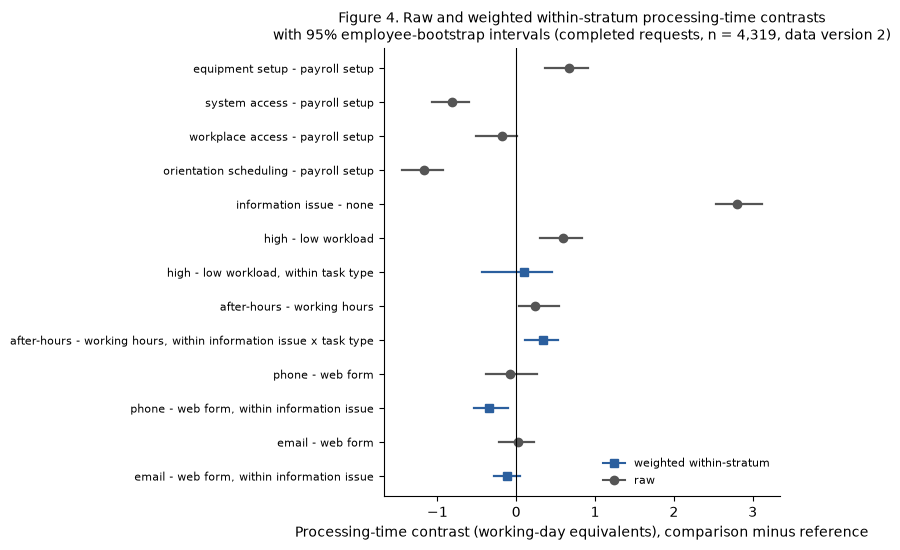

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.6))
plot = intervals.iloc[::-1].reset_index(drop=True)
for i, row in plot.iterrows():
    weighted = row["summary"] != "raw"
    if row["interval_withheld"]:
        ax.annotate("interval withheld", (row["estimate_days"], i), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=7, color="#b0362b")
    else:
        ax.plot([row["ci_low"], row["ci_high"]], [i, i], color="#2b5f9e" if weighted else "#555555", lw=1.6)
    ax.plot(row["estimate_days"], i, marker="s" if weighted else "o", color="#2b5f9e" if weighted else "#555555",
            markersize=6, label="weighted within-stratum" if weighted else "raw")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(plot)), plot["contrast"].str.replace("_", " "), fontsize=8)
ax.set_xlabel("Processing-time contrast (working-day equivalents), comparison minus reference")
ax.set_title("Figure 4. Raw and weighted within-stratum processing-time contrasts\n"
             f"with 95% employee-bootstrap intervals (completed requests, n = {len(d):,}, data version 2)", fontsize=10)
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), fontsize=8, frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "contrast_intervals.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 4 caption.** *What it shows:* the 13 processing-time contrasts specified before the bootstrap analysis (comparison minus reference, in working-day equivalents), with 95% intervals from resampling whole employees. Grey circles are raw median differences; blue squares are weighted within-stratum median differences for the same comparison. The weighted workload comparison covers the four task types that have requests in both workload groups (84.6% of completed requests). The full-sample raw workload contrast and the weighted contrast differ in both population coverage and statistical summary; on the same four task types the raw contrast is +0.75 days (section C), so the comparison on a common population is +0.75 raw against +0.09 weighted. Intervals are individual, not simultaneous, and a withheld interval would be labelled on the chart. *Why it matters:* it shows which differences are large relative to their uncertainty, and whether comparing within a common mix of task type or information issue changes a raw difference. *What it can't establish:* why groups differ, or whether a factor causes a delay; the intervals do not account for shared busy periods or team workload, so they may be too narrow; the results describe completed requests in generated data.